# Model Development — Train, Validation and Test
**Student:** Mathonsi Mphikeleli Mbongiseni (28574249) · UNISA MCom Quantitative Management

Assets: MSFT, AAPL, NVDA, IBM, CSCO, JPM, BAC, C · Period: Jan 2010 – Dec 2025

This notebook is a companion to `Model Development.ipynb`. The existing notebook uses a two-way split (80% in-sample, 20% out-of-sample) and lets Keras carve a validation slice out of the training sequences. Here the split is made explicit and three-way: a **training** set on which the GARCH-family models and the LSTM are fitted, a **validation** set on which the LSTM architecture is chosen and early stopping is decided, and a **test** set that is touched only once, for the final evaluation. The test window is identical to the existing notebook's, so the two can be compared directly.

Two ways of supervising the LSTM are compared on the same split and the same architecture: against the **realised volatility** that followed each day (the existing methodology), and against the **volatility the GARCH models themselves produced** over the training period. The existing notebooks, models and result files are not modified; every new output carries a `tvt_` prefix.

## 1. Setup

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'torch'

import warnings
import pickle
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

from arch import arch_model
from arch.univariate import StudentsT
import keras
from keras import layers

warnings.filterwarnings('ignore')
pd.set_option('display.float_format', '{:.6f}'.format)
np.random.seed(42)
keras.utils.set_random_seed(42)

ROOT        = Path(r'e:\Academic & Research\Msc in Quantitative Management\Research Codes')
DATA_DIR    = ROOT / 'data'
FIGURES_DIR = ROOT / 'figures'
TABLES_DIR  = ROOT / 'tables'
MODELS_DIR  = ROOT / 'models'
RESULTS_DIR = ROOT / 'results'

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 10,
})

STOCKS       = ['AAPL', 'BAC', 'C', 'CSCO', 'IBM', 'JPM', 'MSFT', 'NVDA']
TRADING_DAYS = 252
CONF_LEVELS  = [0.95, 0.99]
REFIT_FREQ   = 63
TRAIN_FRAC   = 0.65
TEST_FRAC    = 0.20
EPS          = 1e-8
SEED         = 42
DROPOUT      = 0.2
GRID_LOOKBACK = [10, 21]
GRID_UNITS    = [16, 32]
GARCH_NAMES  = ['GARCH', 'EGARCH', 'GJR-GARCH']
MODEL_NAMES  = GARCH_NAMES + ['Hybrid (realised target)', 'Hybrid (GARCH target)']
COLORS = {'GARCH': '#D65F5F', 'EGARCH': '#4878CF', 'GJR-GARCH': '#6ACC65',
          'Hybrid (realised target)': '#8172B2', 'Hybrid (GARCH target)': '#CCB974'}
SPECS = {'GARCH': ('GARCH', 0), 'EGARCH': ('EGARCH', 1), 'GJR-GARCH': ('GARCH', 1)}

def seeded_arch_model(y, vol, o, seed):
    # simulated innovations are drawn from the distribution object, so the seed is attached there
    am = arch_model(y, mean='Constant', vol=vol, p=1, o=o, q=1, dist='t')
    am.distribution = StudentsT(seed=np.random.RandomState(seed))
    return am

print('Keras backend:', keras.backend.backend())


Keras backend: torch


## 2. Data Preparation

In [2]:
ret         = pd.read_csv(DATA_DIR / 'log_returns_clean.csv', index_col='Date', parse_dates=True)
portfolio   = ret[STOCKS].mean(axis=1).rename('PORTFOLIO')
returns_pct = portfolio * 100
N           = len(portfolio)
pos_of      = {d: i for i, d in enumerate(portfolio.index)}

assert portfolio.notna().all() and portfolio.index.is_monotonic_increasing and not portfolio.index.duplicated().any()
print(f"Portfolio observations: {N}   {portfolio.index.min().date()} to {portfolio.index.max().date()}")
print(f"Annualised volatility : {portfolio.std() * np.sqrt(TRADING_DAYS) * 100:.2f}%   Ex. kurtosis: {portfolio.kurtosis():.2f}")


Portfolio observations: 4022   2010-01-05 to 2025-12-30
Annualised volatility : 22.58%   Ex. kurtosis: 11.48


## 3. Three-Way Chronological Split

The final 20% of the sample is the test set, exactly as in the existing notebook. The first 80% is divided into a training set (65% of the sample) and a validation set (15%). The training share is deliberately large enough to contain the March 2020 crash: a volatility model trained only on the calm decade before it would never have seen a stress regime, and the validation set would then be dominated by that one event. Nothing is shuffled. GARCH parameters and LSTM weights are estimated on the training set, the validation set decides the LSTM configuration, and the test set is used once. Sequences are assigned to a set by the date of the return being forecast, and the one sequence at each boundary whose target lies in the next set is dropped, so that no training target is a validation return and no validation target is a test return.

In [3]:
n_train      = int(N * TRAIN_FRAC)
n_test_start = int(N * (1 - TEST_FRAC))

train_idx = portfolio.index[:n_train]
val_idx   = portfolio.index[n_train:n_test_start]
test_idx  = portfolio.index[n_test_start:]

split_summary = pd.DataFrame({
    'Start':        [train_idx[0].date(), val_idx[0].date(), test_idx[0].date()],
    'End':          [train_idx[-1].date(), val_idx[-1].date(), test_idx[-1].date()],
    'Observations': [len(train_idx), len(val_idx), len(test_idx)],
    'Share (%)':    [len(train_idx) / N * 100, len(val_idx) / N * 100, len(test_idx) / N * 100],
    'Ann. vol (%)': [portfolio.loc[i].std() * np.sqrt(TRADING_DAYS) * 100 for i in (train_idx, val_idx, test_idx)],
}, index=['Train', 'Validation', 'Test'])
print(split_summary.round(2).to_string())
split_summary.to_csv(TABLES_DIR / 'tvt_split_summary.csv')


                 Start         End  Observations  Share (%)  Ann. vol (%)
Train       2010-01-05  2020-05-22          2614  64.990000     23.430000
Validation  2020-05-26  2022-10-13           603  14.990000     23.050000
Test        2022-10-14  2025-12-30           805  20.010000     19.150000


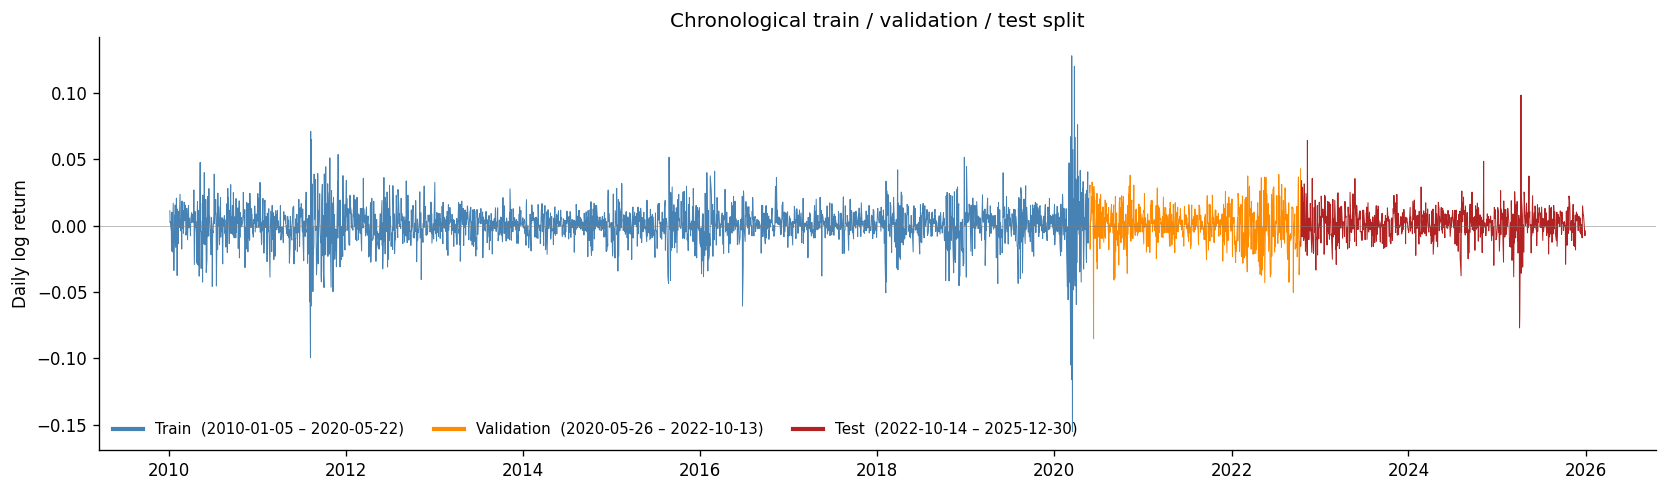

In [4]:
fig, ax = plt.subplots(figsize=(14, 4.2))
for idx, color, label in [(train_idx, 'steelblue', 'Train'), (val_idx, 'darkorange', 'Validation'), (test_idx, 'firebrick', 'Test')]:
    ax.plot(portfolio.loc[idx], color=color, lw=0.6, label=f"{label}  ({idx[0].date()} – {idx[-1].date()})")
ax.axhline(0, color='grey', lw=0.3)
ax.set_title('Chronological train / validation / test split')
ax.set_ylabel('Daily log return')
legend = ax.legend(frameon=False, fontsize=9, ncol=3, loc='lower left')
for line in legend.get_lines():
    line.set_linewidth(2.5)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_split.png', bbox_inches='tight')
plt.show()


## 4. GARCH Layer

### 4.1 Estimation on the training set

GARCH(1,1), EGARCH(1,1) and GJR-GARCH(1,1) with Student-t innovations are first estimated on the training set only. Their fitted conditional volatility over the training window is the volatility "that would have happened" in-sample, and it is what the LSTM sees, and in one of the two variants is trained to reproduce, during training.

In [5]:
train_fits = {name: seeded_arch_model(returns_pct.loc[train_idx], vol, o, SEED).fit(disp='off')
              for name, (vol, o) in SPECS.items()}

for name, res in train_fits.items():
    print(f"\n{name}(1,1)-t — training-set estimates")
    print(res.params.round(4).to_string())
    print(f"Log-likelihood: {res.loglikelihood:.2f}   AIC: {res.aic:.2f}   BIC: {res.bic:.2f}")



GARCH(1,1)-t — training-set estimates
mu         0.119000
omega      0.048500
alpha[1]   0.133700
beta[1]    0.847300
nu         5.468800
Log-likelihood: -4080.46   AIC: 8170.91   BIC: 8200.26

EGARCH(1,1)-t — training-set estimates
mu          0.088500
omega       0.016300
alpha[1]    0.183400
gamma[1]   -0.140100
beta[1]     0.966300
nu          5.690400
Log-likelihood: -4049.29   AIC: 8110.59   BIC: 8145.80

GJR-GARCH(1,1)-t — training-set estimates
mu         0.092900
omega      0.061300
alpha[1]   0.013900
gamma[1]   0.204200
beta[1]    0.848200
nu         5.751100
Log-likelihood: -4050.70   AIC: 8113.41   BIC: 8148.62


### 4.2 Walk-forward forecasts over the validation and test sets

Beyond the training set, each model is re-estimated on an expanding window every 63 trading days and forecasts the following block, as in the existing notebook. The validation and test periods are run as two separate walk-forward passes, so the test pass starts with a fresh estimation on all data up to the first test day, exactly as it does in the existing notebook; the validation pass therefore reproduces test-time conditions on data the test set never sees. The simulation used by `arch` for multi-step EGARCH forecasts is seeded, so the forecasts are reproducible. Note that these are multi-step forecasts made at the start of each block: they do not use returns observed after the block begins. Section 7.5 examines what this implies for the comparison with the LSTM.

In [6]:
def walk_forward_garch(period_idx, vol, o, refit_freq=REFIT_FREQ):
    origin  = pos_of[period_idx[0]]
    var_hat = pd.Series(index=period_idx, dtype=float)
    nu_hat  = pd.Series(index=period_idx, dtype=float)
    for start in range(0, len(period_idx), refit_freq):
        end    = min(start + refit_freq, len(period_idx))
        block  = period_idx[start:end]
        window = returns_pct.index[:origin + start]
        res = seeded_arch_model(returns_pct.loc[window], vol, o, SEED + origin + start).fit(disp='off')
        method = 'simulation' if vol == 'EGARCH' else 'analytic'
        fc = res.forecast(horizon=len(block), reindex=False, method=method, simulations=1000)
        var_hat.loc[block] = fc.variance.values[0][:len(block)] / 1e4
        nu_hat.loc[block]  = res.params['nu']
    return var_hat, nu_hat

wf_var, wf_nu = {}, {}
for name, (vol, o) in SPECS.items():
    v_val,  n_val  = walk_forward_garch(val_idx,  vol, o)
    v_test, n_test = walk_forward_garch(test_idx, vol, o)
    wf_var[name] = pd.concat([v_val, v_test])
    wf_nu[name]  = pd.concat([n_val, n_test])

print(f"Walk-forward forecasts: {len(val_idx)} validation days and {len(test_idx)} test days for {len(SPECS)} models")


Walk-forward forecasts: 603 validation days and 805 test days for 3 models


### 4.3 The volatility path over all three sets

For every day the notebook keeps two things: the conditional variance the model assigns to that day (fitted in-sample over the training set, forecast walk-forward afterwards), and the Student-t degrees of freedom in force. The one-day-ahead forecast made at the close of day $t$ is the variance assigned to day $t+1$, which is what all VaR figures below are built from.

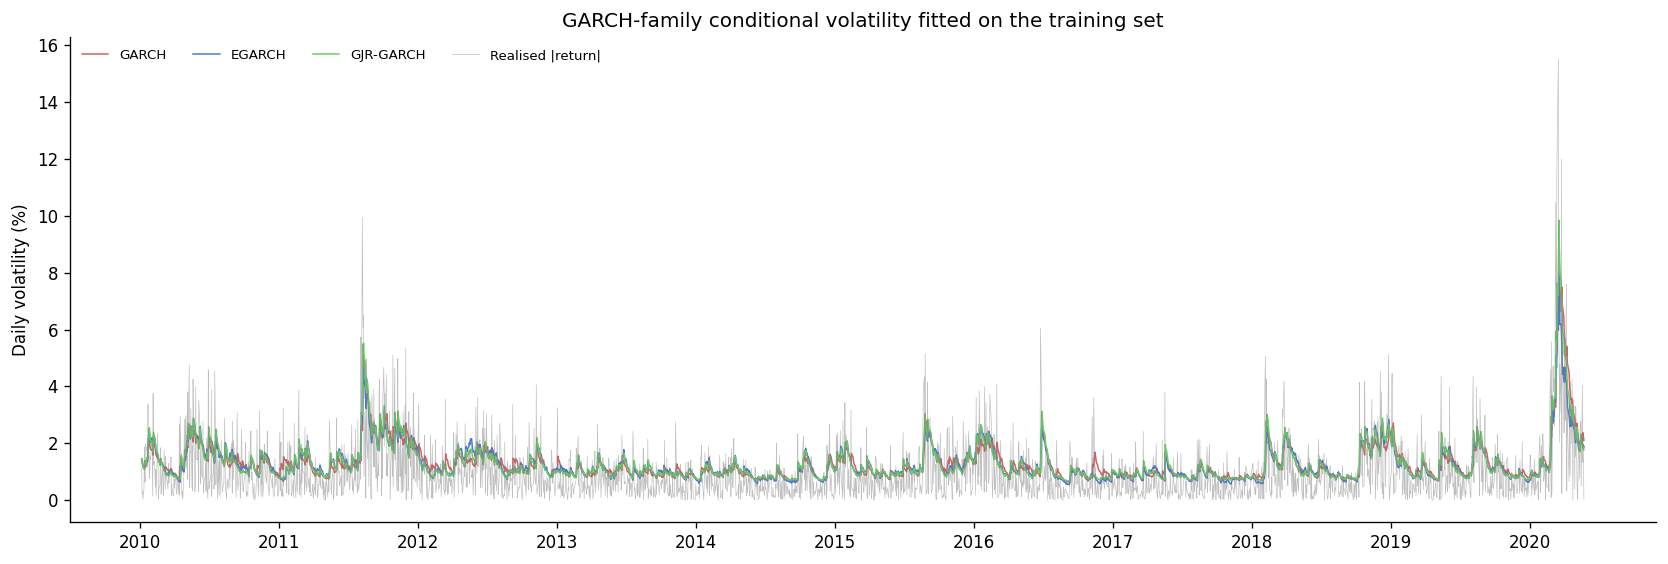

In [7]:
var_day, vol_day = {}, {}
for name in GARCH_NAMES:
    in_sample_var = (train_fits[name].conditional_volatility / 100) ** 2
    var_day[name] = pd.concat([in_sample_var, wf_var[name]])
    vol_day[name] = np.sqrt(var_day[name])
    assert var_day[name].index.equals(portfolio.index) and var_day[name].notna().all()

next_vol = {name: vol_day[name].shift(-1) for name in GARCH_NAMES}
realised_next = portfolio.shift(-1).abs()

fig, ax = plt.subplots(figsize=(14, 4.8))
for name in GARCH_NAMES:
    ax.plot(vol_day[name].loc[train_idx] * 100, color=COLORS[name], lw=0.9, label=name)
ax.plot(portfolio.abs().loc[train_idx] * 100, color='grey', lw=0.4, alpha=0.5, label='Realised |return|')
ax.set_ylabel('Daily volatility (%)')
ax.set_title('GARCH-family conditional volatility fitted on the training set')
ax.legend(frameon=False, fontsize=8, ncol=4)
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_garch_training_fit.png', bbox_inches='tight')
plt.show()


## 5. LSTM Inputs and Targets

The LSTM input at day $t$ is a sequence of seven daily values: the return, the conditional volatility of each GARCH model and the standardised residual $r_t/\sigma_t$ implied by each. Two supervision targets are built for the same inputs:

- **Realised-volatility target** (the existing methodology): $\log(r_{t+1}^2+\varepsilon)$.
- **GARCH target**: the log of the average conditional variance of the three GARCH models for day $t+1$, that is, the volatility the classical layer itself produced. Over the training set this is a deterministic function of the inputs, so it tests how much of the LSTM's behaviour is simply reproducing GARCH.

In [8]:
KEYS = {'GARCH': 'garch', 'EGARCH': 'egarch', 'GJR-GARCH': 'gjr'}

feat = pd.DataFrame({'return': portfolio})
for name in GARCH_NAMES:
    feat[f'{KEYS[name]}_vol'] = vol_day[name]
for name in GARCH_NAMES:
    feat[f'{KEYS[name]}_sr'] = portfolio / vol_day[name]
FEATURE_COLS = list(feat.columns)
N_FEATURES   = len(FEATURE_COLS)

ensemble_var = sum(var_day[name] for name in GARCH_NAMES) / len(GARCH_NAMES)
target_realised = np.log(portfolio.shift(-1) ** 2 + EPS)
target_garch    = np.log(ensemble_var.shift(-1))

print(f"Feature columns ({N_FEATURES}): {FEATURE_COLS}")
print(f"Missing values in inputs: {feat.isna().sum().sum()}")


Feature columns (7): ['return', 'garch_vol', 'egarch_vol', 'gjr_vol', 'garch_sr', 'egarch_sr', 'gjr_sr']
Missing values in inputs: 0


In [9]:
def build_sequences(target, lookback):
    values = feat.values
    X, y, origins = [], [], []
    for pos in range(lookback - 1, N):
        t = target.iloc[pos]
        if np.isnan(t):
            continue
        X.append(values[pos - lookback + 1: pos + 1])
        y.append(t)
        origins.append(pos)
    return np.array(X, dtype='float32'), np.array(y, dtype='float32'), np.array(origins)

def split_masks(origins):
    return {'Train':      origins <= n_train - 2,
            'Validation': (origins >= n_train) & (origins <= n_test_start - 2),
            'Test':       origins >= n_test_start}

def prepare(target, lookback):
    X, y, origins = build_sequences(target, lookback)
    masks  = split_masks(origins)
    scaler = StandardScaler().fit(X[masks['Train']].reshape(-1, N_FEATURES))
    scale  = lambda a: scaler.transform(a.reshape(-1, N_FEATURES)).reshape(a.shape).astype('float32')
    data = {k: {'X': scale(X[m]), 'y': y[m], 'dates': portfolio.index[origins[m]]} for k, m in masks.items()}
    return data, scaler

demo, _ = prepare(target_realised, 21)
print({k: v['X'].shape for k, v in demo.items()})


{'Train': (2593, 21, 7), 'Validation': (602, 21, 7), 'Test': (804, 21, 7)}


## 6. Training and Validation

### 6.1 Realised-volatility supervision: architecture chosen on the validation set

Four LSTM configurations (look-back window of 10 or 21 days, 16 or 32 units) are trained on the training sequences with the realised-volatility target. Early stopping monitors the loss on the explicit validation set, not on a slice of the training data, and the configuration with the lowest validation error is kept. The scaler is fitted on the training sequences of each configuration only.

In [10]:
def make_lstm(lookback, units):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([
        layers.Input(shape=(lookback, N_FEATURES)),
        layers.LSTM(units),
        layers.Dropout(DROPOUT),
        layers.Dense(16, activation='relu'),
        layers.Dense(1),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model

def fit_lstm(target, lookback, units):
    data, scaler = prepare(target, lookback)
    model = make_lstm(lookback, units)
    history = model.fit(
        data['Train']['X'], data['Train']['y'],
        validation_data=(data['Validation']['X'], data['Validation']['y']),
        epochs=100, batch_size=32, shuffle=True, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)])
    return model, history, data, scaler

grid_runs, grid_rows = {}, []
for lookback in GRID_LOOKBACK:
    for units in GRID_UNITS:
        model, history, data, scaler = fit_lstm(target_realised, lookback, units)
        best_epoch = int(np.argmin(history.history['val_loss']))
        grid_runs[(lookback, units)] = (model, history, data, scaler)
        grid_rows.append({'Look-back': lookback, 'Units': units, 'Epochs run': len(history.history['loss']),
                          'Best epoch': best_epoch + 1,
                          'Train MSE': history.history['loss'][best_epoch],
                          'Validation MSE': history.history['val_loss'][best_epoch]})

grid_df = pd.DataFrame(grid_rows).set_index(['Look-back', 'Units'])
best_key = grid_df['Validation MSE'].idxmin()
print(grid_df.round(4).to_string())
print(f"\nSelected on the validation set: look-back {best_key[0]}, {best_key[1]} units")
grid_df.to_csv(TABLES_DIR / 'tvt_grid_search.csv')


                 Epochs run  Best epoch  Train MSE  Validation MSE
Look-back Units                                                   
10        16             19           9   6.509700        4.673000
          32             39          29   5.490600        4.605300
21        16             34          24   5.681800        4.702300
          32             38          28   5.459100        4.608900

Selected on the validation set: look-back 10, 32 units


### 6.2 GARCH supervision: same architecture, different target

To isolate the effect of what the LSTM is trained against, the selected architecture is trained again with the GARCH target, on the same split and with the same early-stopping rule.

In [11]:
LOOKBACK, UNITS = (int(v) for v in best_key)
model_a, history_a, data_a, scaler_a = grid_runs[(LOOKBACK, UNITS)]
model_b, history_b, data_b, scaler_b = fit_lstm(target_garch, LOOKBACK, UNITS)

for label, h in [('Realised target', history_a), ('GARCH target', history_b)]:
    best = int(np.argmin(h.history['val_loss']))
    print(f"{label:16s} epochs run {len(h.history['loss']):3d}   best epoch {best + 1:3d}   "
          f"train MSE {h.history['loss'][best]:.4f}   validation MSE {h.history['val_loss'][best]:.4f}")


Realised target  epochs run  39   best epoch  29   train MSE 5.4906   validation MSE 4.6053
GARCH target     epochs run  22   best epoch  12   train MSE 0.6470   validation MSE 0.0694


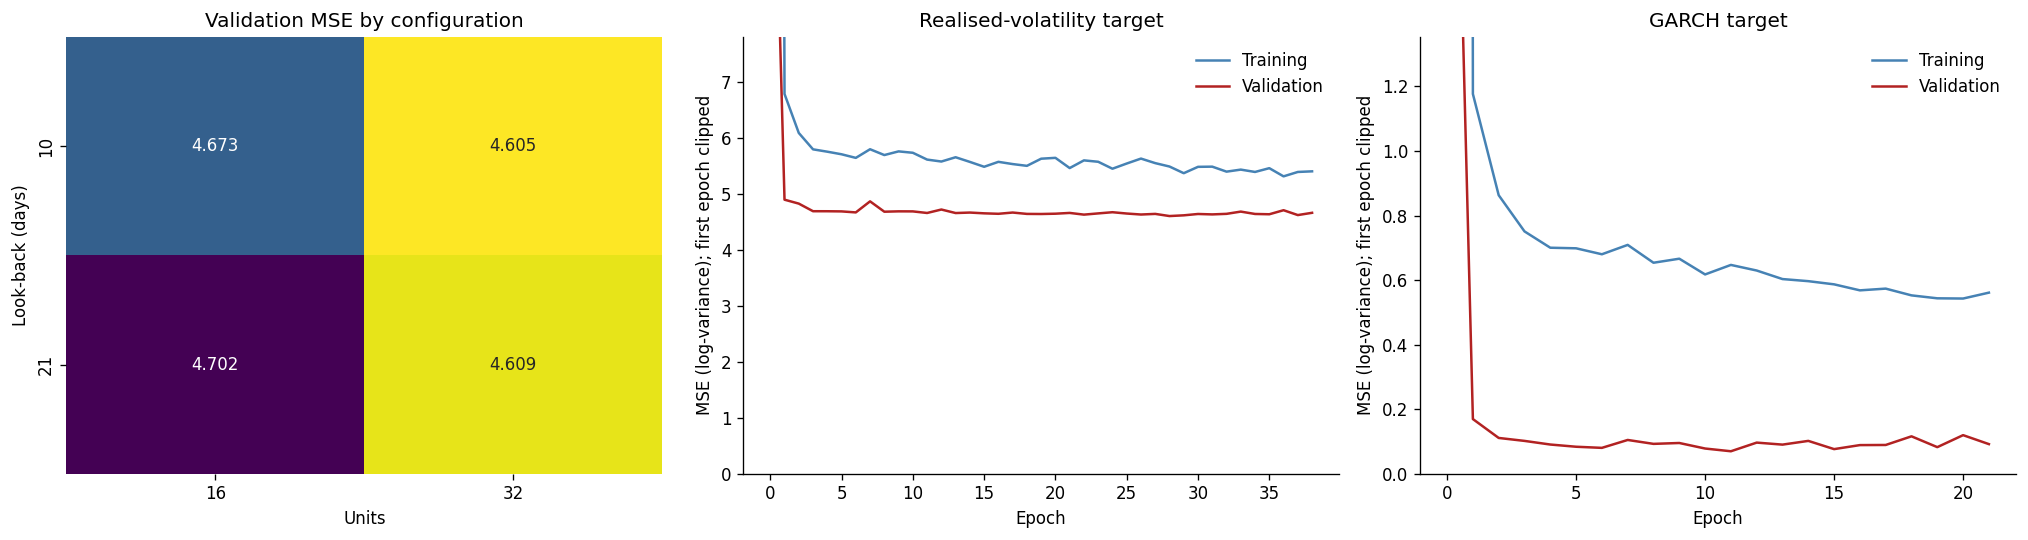

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
pivot = grid_df['Validation MSE'].unstack('Units')
sns.heatmap(pivot, annot=True, fmt='.3f', cmap='viridis_r', cbar=False, ax=axes[0])
axes[0].set_title('Validation MSE by configuration')
axes[0].set_ylabel('Look-back (days)')
for ax, h, title in [(axes[1], history_a, 'Realised-volatility target'), (axes[2], history_b, 'GARCH target')]:
    ax.plot(h.history['loss'], color='steelblue', label='Training')
    ax.plot(h.history['val_loss'], color='firebrick', label='Validation')
    tail = np.concatenate([h.history['loss'][1:], h.history['val_loss'][1:]])
    ax.set_ylim(0, tail.max() * 1.15)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE (log-variance); first epoch clipped')
    ax.set_title(title)
    ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_learning_curves.png', bbox_inches='tight')
plt.show()


### 6.3 From log-variance to volatility

Both networks predict a log-variance, so their output is exponentiated and corrected for retransformation bias with the Duan (1983) smearing factor, computed from each network's **training-set** residuals only.

In [13]:
def hybrid_sigma(model, data):
    train_resid = data['Train']['y'] - model.predict(data['Train']['X'], verbose=0).flatten()
    smear = float(np.mean(np.exp(train_resid)))
    out = {split: pd.Series(np.sqrt(np.exp(model.predict(d['X'], verbose=0).flatten()) * smear), index=d['dates'])
           for split, d in data.items()}
    return out, smear

sigma_a, smear_a = hybrid_sigma(model_a, data_a)
sigma_b, smear_b = hybrid_sigma(model_b, data_b)
print(f"Smearing factor — realised target: {smear_a:.4f}   GARCH target: {smear_b:.4f}")

fidelity = pd.Series({split: r2_score(d['y'], np.log(sigma_b[split].values ** 2 / smear_b))
                      for split, d in data_b.items()}, name='R2 against the GARCH target')
print(fidelity.round(4).to_string())


Smearing factor — realised target: 3.4019   GARCH target: 0.9586
Train        0.970300
Validation   0.553400
Test         0.633000


## 7. Evaluation

Every model is scored on the same dates within each split. For a forecast origin $t$ the quantity being predicted is the volatility of day $t+1$; the realised proxy is $|r_{t+1}|$. For the GARCH models the prediction is the conditional volatility assigned to day $t+1$ (in-sample over the training set, walk-forward afterwards).

### 7.1 Accuracy by split

In [14]:
dates_by_split = {k: data_a[k]['dates'] for k in ('Train', 'Validation', 'Test')}

def predicted_vol(name, split):
    dates = dates_by_split[split]
    if name in GARCH_NAMES:
        return next_vol[name].reindex(dates)
    src = sigma_a if name == 'Hybrid (realised target)' else sigma_b
    return src[split].reindex(dates)

def accuracy(pred, realised):
    return {'RMSE': np.sqrt(np.mean((pred - realised) ** 2)),
            'MAE':  mean_absolute_error(realised, pred),
            'R2':   r2_score(realised, pred)}

rows = []
for split in ('Train', 'Validation', 'Test'):
    realised = realised_next.reindex(dates_by_split[split])
    for name in MODEL_NAMES:
        rows.append({'Split': split, 'Model': name, **accuracy(predicted_vol(name, split), realised)})
by_split = pd.DataFrame(rows)

print(by_split.pivot(index='Model', columns='Split', values='RMSE')[['Train', 'Validation', 'Test']].loc[MODEL_NAMES].round(5).to_string())
print()
print(by_split.pivot(index='Model', columns='Split', values='R2')[['Train', 'Validation', 'Test']].loc[MODEL_NAMES].round(4).to_string())
by_split.to_csv(RESULTS_DIR / 'tvt_model_performance_by_split.csv', index=False)


Split                       Train  Validation     Test
Model                                                 
GARCH                    0.010070    0.010530 0.010820
EGARCH                   0.009750    0.009800 0.009570
GJR-GARCH                0.009870    0.009800 0.009930
Hybrid (realised target) 0.010230    0.009850 0.009530
Hybrid (GARCH target)    0.009920    0.009760 0.009550

Split                       Train  Validation      Test
Model                                                  
GARCH                    0.172700   -0.206500 -0.609300
EGARCH                   0.224300   -0.045200 -0.258000
GJR-GARCH                0.205300   -0.044700 -0.354500
Hybrid (realised target) 0.146700   -0.054400 -0.249100
Hybrid (GARCH target)    0.197800   -0.036800 -0.252900


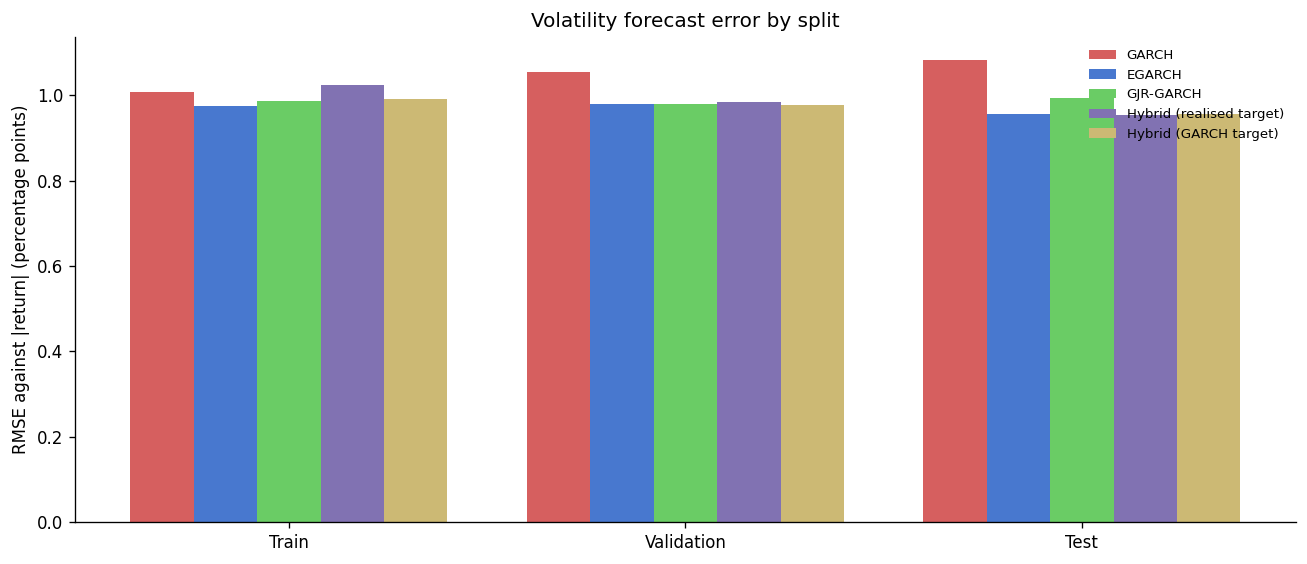

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.8))
width = 0.16
for k, name in enumerate(MODEL_NAMES):
    vals = [by_split[(by_split['Split'] == s) & (by_split['Model'] == name)]['RMSE'].iloc[0] * 100
            for s in ('Train', 'Validation', 'Test')]
    ax.bar(np.arange(3) + (k - 2) * width, vals, width, color=COLORS[name], label=name)
ax.set_xticks(range(3))
ax.set_xticklabels(['Train', 'Validation', 'Test'])
ax.set_ylabel('RMSE against |return| (percentage points)')
ax.set_title('Volatility forecast error by split')
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_rmse_by_split.png', bbox_inches='tight')
plt.show()


### 7.2 Test-set volatility forecast accuracy

In [16]:
realised_test = realised_next.reindex(dates_by_split['Test'])
N_PARAMS = {'GARCH': 3, 'EGARCH': 4, 'GJR-GARCH': 4, 'Hybrid (realised target)': N_FEATURES, 'Hybrid (GARCH target)': N_FEATURES}

test_rows = []
for name in MODEL_NAMES:
    pred = predicted_vol(name, 'Test')
    r2 = r2_score(realised_test, pred)
    n, p = len(realised_test), N_PARAMS[name]
    test_rows.append({
        'Model': name,
        'RMSE': np.sqrt(np.mean((pred - realised_test) ** 2)),
        'MAE': mean_absolute_error(realised_test, pred),
        'MAPE': mean_absolute_percentage_error(realised_test.clip(lower=1e-4), pred.clip(lower=1e-4)),
        'R2': r2, 'Adj. R2': 1 - (1 - r2) * (n - 1) / (n - p - 1),
        'Directional Acc. (%)': (np.sign(pred.diff()) == np.sign(realised_test.diff())).mean() * 100})
test_perf = pd.DataFrame(test_rows).set_index('Model')
print(test_perf.round(4).to_string())

existing_perf = pd.read_csv(RESULTS_DIR / 'model_performance_metrics.csv', index_col=0)
print("\nReference — existing pipeline (Model Development.ipynb), same test window:")
print(existing_perf.round(4).to_string())


                             RMSE      MAE     MAPE        R2   Adj. R2  Directional Acc. (%)
Model                                                                                        
GARCH                    0.010800 0.008500 5.248300 -0.609300 -0.615400             50.248800
EGARCH                   0.009600 0.007300 4.586900 -0.258000 -0.264300             48.756200
GJR-GARCH                0.009900 0.007600 4.766000 -0.354500 -0.361300             49.253700
Hybrid (realised target) 0.009500 0.007200 4.335100 -0.249100 -0.260100             54.228900
Hybrid (GARCH target)    0.009500 0.007400 4.534000 -0.252900 -0.264000             44.527400

Reference — existing pipeline (Model Development.ipynb), same test window:
              RMSE      MAE     MAPE        R2   Adj. R2  Directional Acc. (%)
Model                                                                         
EGARCH    0.009600 0.007400 4.622400 -0.274600 -0.281000             50.497500
Hybrid    0.009800 0.007200 4

### 7.3 VaR backtests

VaR is built from each model's one-day-ahead volatility with a Student-t quantile and the trailing 252-day mean, as in the existing notebook. To keep the tail assumption from being mixed up with the volatility forecast, both Hybrid variants use the average of the three GARCH models' fitted degrees of freedom in force on each day, rather than a separate fixed value; each GARCH model uses its own. The same backtests are applied to the validation set, which was used for model selection, and to the test set, which was not.

In [17]:
def t_quantile(alpha, nu):
    return stats.t.ppf(alpha, df=nu) * np.sqrt((nu - 2) / nu)

def t_expected_shortfall(alpha, nu):
    q = stats.t.ppf(alpha, df=nu)
    es_raw = -(stats.t.pdf(q, df=nu) * (nu + q ** 2)) / (alpha * (nu - 1))
    return es_raw * np.sqrt((nu - 2) / nu)

def kupiec_test(violations, alpha):
    T, x = len(violations), int(violations.sum())
    pi_hat = np.clip(x / T, 1e-6, 1 - 1e-6)
    ll_null = (T - x) * np.log(1 - alpha) + x * np.log(alpha)
    ll_alt  = (T - x) * np.log(1 - pi_hat) + x * np.log(pi_hat)
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1)

def christoffersen_test(violations):
    v = np.asarray(violations).astype(int)
    n00 = n01 = n10 = n11 = 0
    for prev, cur in zip(v[:-1], v[1:]):
        n00 += prev == 0 and cur == 0
        n01 += prev == 0 and cur == 1
        n10 += prev == 1 and cur == 0
        n11 += prev == 1 and cur == 1
    pi01 = n01 / (n00 + n01) if (n00 + n01) else 0.0
    pi11 = n11 / (n10 + n11) if (n10 + n11) else 0.0
    pi   = (n01 + n11) / (n00 + n01 + n10 + n11)
    safe_log = lambda x: np.log(np.clip(x, 1e-10, 1 - 1e-10))
    ll_null = (n00 + n10) * safe_log(1 - pi) + (n01 + n11) * safe_log(pi)
    ll_alt  = n00 * safe_log(1 - pi01) + n01 * safe_log(pi01) + n10 * safe_log(1 - pi11) + n11 * safe_log(pi11)
    lr = -2 * (ll_null - ll_alt)
    return lr, 1 - stats.chi2.cdf(lr, df=1)

def es_backtest_ratio(actual, var_est, es_est):
    breach = actual < -var_est
    return np.nan if breach.sum() == 0 else (-actual[breach]).mean() / es_est[breach].mean()

mu_roll    = portfolio.rolling(TRADING_DAYS).mean()
nu_next    = {name: wf_nu[name].shift(-1) for name in GARCH_NAMES}
nu_common  = pd.concat(nu_next.values(), axis=1).mean(axis=1)
actual_all = portfolio.shift(-1)

def var_es(name, split, cl):
    dates = dates_by_split[split]
    nu    = (nu_next[name] if name in GARCH_NAMES else nu_common).reindex(dates)
    sig   = predicted_vol(name, split)
    mu    = mu_roll.reindex(dates)
    alpha = 1 - cl
    return -(mu + sig * t_quantile(alpha, nu)), -(mu + sig * t_expected_shortfall(alpha, nu))

bt_rows, var_store = [], {}
for split in ('Validation', 'Test'):
    actual = actual_all.reindex(dates_by_split[split])
    for name in MODEL_NAMES:
        for cl in CONF_LEVELS:
            v_est, es_est = var_es(name, split, cl)
            var_store[(split, name, cl)] = v_est
            viol = actual < -v_est
            lr_p, p_p = kupiec_test(viol, 1 - cl)
            lr_i, p_i = christoffersen_test(viol)
            bt_rows.append({'Split': split, 'Model': name, 'CL': cl, 'Violations': int(viol.sum()),
                            'Violation Rate (%)': viol.mean() * 100, 'Kupiec p': p_p,
                            'Christoffersen p': p_i, 'ES Ratio': es_backtest_ratio(actual, v_est, es_est)})

backtest_tvt = pd.DataFrame(bt_rows)
for split in ('Validation', 'Test'):
    print(f"\n{split} set")
    print(backtest_tvt[backtest_tvt['Split'] == split].drop(columns='Split').set_index(['Model', 'CL']).round(4).to_string())
backtest_tvt.to_csv(RESULTS_DIR / 'tvt_var_backtest_summary.csv', index=False)



Validation set
                                   Violations  Violation Rate (%)  Kupiec p  Christoffersen p  ES Ratio
Model                    CL                                                                            
GARCH                    0.950000          34            5.647800  0.474500          0.441300  1.055700
                         0.990000           9            1.495000  0.255400          0.600900  1.013500
EGARCH                   0.950000          40            6.644500  0.077300          0.827500  1.064900
                         0.990000          13            2.159500  0.013200          0.448300  0.975300
GJR-GARCH                0.950000          39            6.478400  0.110700          0.712300  1.058800
                         0.990000          12            1.993400  0.030900          0.484400  0.996500
Hybrid (realised target) 0.950000          42            6.976700  0.035200          0.166700  1.070300
                         0.990000          10   

In [18]:
existing_bt = pd.read_csv(RESULTS_DIR / 'var_backtest_summary.csv').set_index(['Model', 'CL'])
print("Reference — existing pipeline (Model Development.ipynb), same test window")
print(existing_bt[['Violations', 'Violation Rate (%)', 'Kupiec p', 'Christoffersen p', 'ES Ratio']].round(4).to_string())


Reference — existing pipeline (Model Development.ipynb), same test window
                    Violations  Violation Rate (%)  Kupiec p  Christoffersen p  ES Ratio
Model     CL                                                                            
EGARCH    0.950000          31            3.855700  0.121500          0.031900  1.119700
          0.990000          11            1.368200  0.320400          0.006800  1.059800
GARCH     0.950000          25            3.109500  0.008400          0.043400  1.105500
          0.990000           6            0.746300  0.449000          0.031500  1.151900
GJR-GARCH 0.950000          32            3.980100  0.169500          0.040300  1.104800
          0.990000           9            1.119400  0.738500          0.084400  1.105300
Hybrid    0.950000          43            5.348300  0.654000          0.829700  0.946200
          0.990000           6            0.746300  0.449000          0.763700  1.033600


### 7.4 Figures

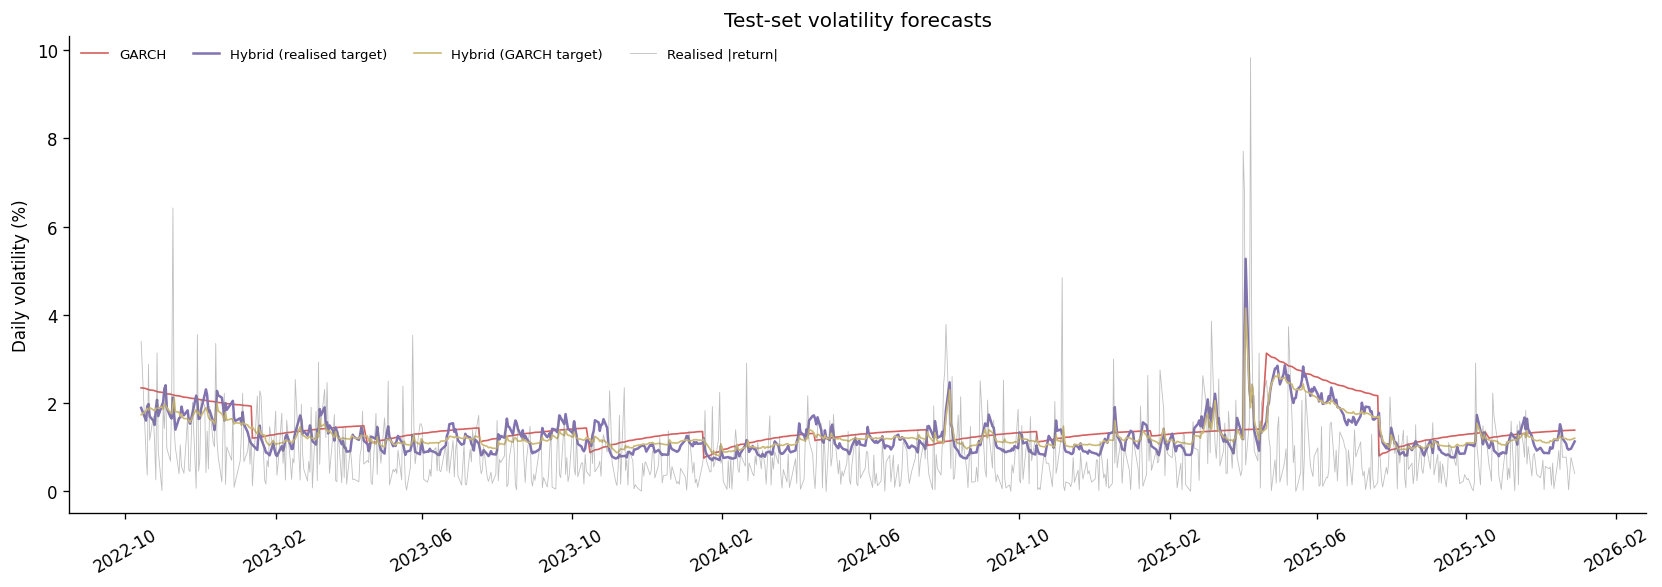

In [19]:
fig, ax = plt.subplots(figsize=(14, 5))
dates = dates_by_split['Test']
for name in ['GARCH', 'Hybrid (realised target)', 'Hybrid (GARCH target)']:
    lw = 1.5 if name.startswith('Hybrid (realised') else 1.0
    ax.plot(dates, predicted_vol(name, 'Test') * 100, color=COLORS[name], lw=lw, label=name)
ax.plot(dates, realised_test * 100, color='grey', lw=0.5, alpha=0.5, label='Realised |return|')
ax.set_ylabel('Daily volatility (%)')
ax.set_title('Test-set volatility forecasts')
ax.legend(frameon=False, fontsize=8, ncol=4)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=4))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_test_volatility_forecasts.png', bbox_inches='tight')
plt.show()


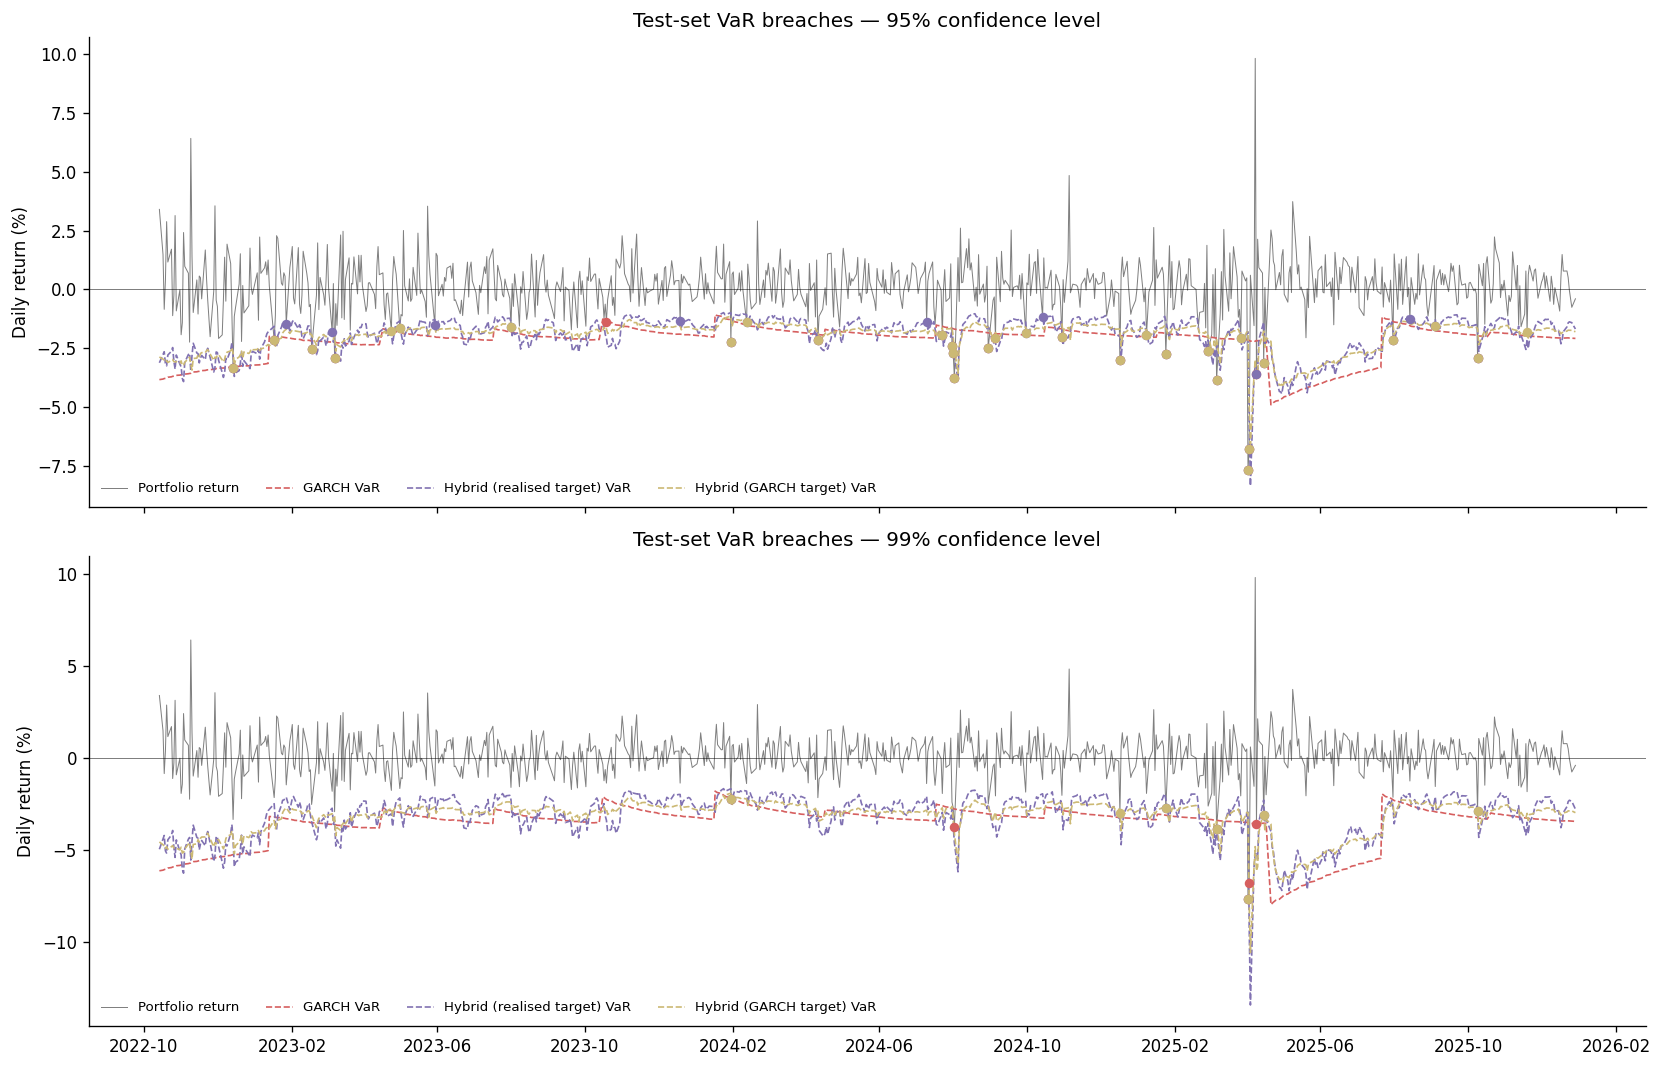

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
actual_test = actual_all.reindex(dates_by_split['Test'])
for ax, cl in zip(axes, CONF_LEVELS):
    ax.plot(dates_by_split['Test'], actual_test * 100, color='grey', lw=0.6, label='Portfolio return')
    for name in ['GARCH', 'Hybrid (realised target)', 'Hybrid (GARCH target)']:
        series = var_store[('Test', name, cl)]
        ax.plot(dates_by_split['Test'], -series * 100, color=COLORS[name], lw=1.0, ls='--', label=f'{name} VaR')
        breach = actual_test < -series
        ax.scatter(dates_by_split['Test'][breach], actual_test[breach] * 100, color=COLORS[name], s=22, zorder=5)
    ax.axhline(0, color='black', lw=0.3)
    ax.set_ylabel('Daily return (%)')
    ax.set_title(f'Test-set VaR breaches — {cl:.0%} confidence level')
    ax.legend(frameon=False, fontsize=8, ncol=4, loc='lower left')
axes[-1].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_test_var_breaches.png', bbox_inches='tight')
plt.show()


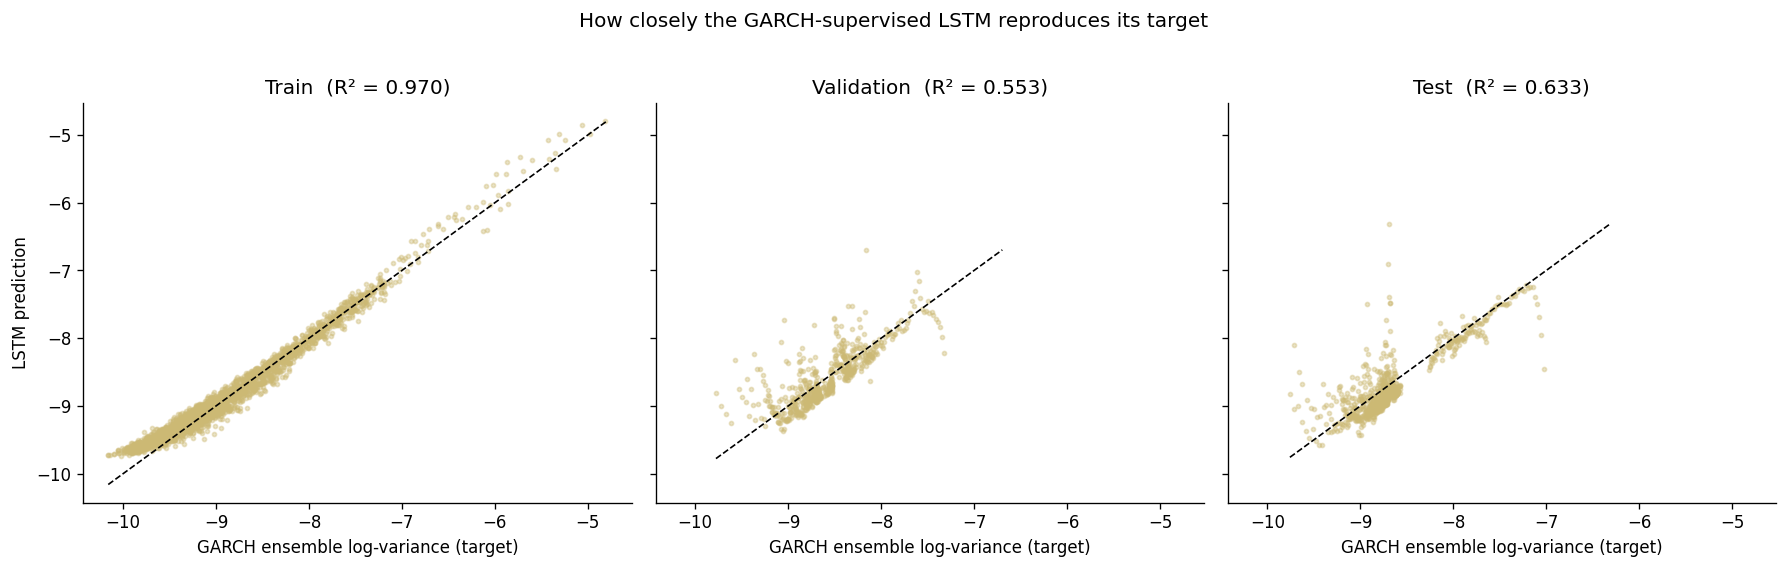

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, split in zip(axes, ('Train', 'Validation', 'Test')):
    d = data_b[split]
    pred = np.log(sigma_b[split].values ** 2 / smear_b)
    ax.scatter(d['y'], pred, s=6, alpha=0.4, color='#CCB974')
    lims = [min(d['y'].min(), pred.min()), max(d['y'].max(), pred.max())]
    ax.plot(lims, lims, 'k--', lw=1)
    ax.set_title(f"{split}  (R² = {r2_score(d['y'], pred):.3f})")
    ax.set_xlabel('GARCH ensemble log-variance (target)')
axes[0].set_ylabel('LSTM prediction')
plt.suptitle('How closely the GARCH-supervised LSTM reproduces its target', y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_garch_target_fidelity.png', bbox_inches='tight')
plt.show()


### 7.5 Sensitivity: GARCH with daily-updated forecasts

In the walk-forward scheme of Section 4.2, each GARCH forecast for a day inside a quarter is a multi-step forecast made at the start of that quarter: it does not use any return observed since. The LSTM, by contrast, is fed the latest returns every day. A comparison between the two therefore mixes the effect of the machine learning layer with the effect of using fresher information. A GARCH model run in production would keep its parameters fixed between re-estimations but update its variance recursion with every new return. That configuration is evaluated here on the same dates, with the same parameter estimates and the same tail assumption as before.

In [22]:
def daily_updated_garch(period_idx, vol, o, refit_freq=REFIT_FREQ):
    origin   = pos_of[period_idx[0]]
    sig_next = pd.Series(index=period_idx, dtype=float)
    for start in range(0, len(period_idx), refit_freq):
        end   = min(start + refit_freq, len(period_idx))
        block = period_idx[start:end]
        fit   = seeded_arch_model(returns_pct.iloc[:origin + start], vol, o, SEED + origin + start).fit(disp='off')
        stop  = min(origin + end + 1, N)
        fixed = seeded_arch_model(returns_pct.iloc[:stop], vol, o, SEED).fix(fit.params)
        cond  = fixed.conditional_volatility / 100
        for t in block:
            i = pos_of[t]
            if i + 1 < N:
                sig_next.loc[t] = cond.iloc[i + 1]
    return sig_next

daily_sigma = {}
for name, (vol, o) in SPECS.items():
    daily_sigma[name] = {'Validation': daily_updated_garch(val_idx, vol, o),
                         'Test':       daily_updated_garch(test_idx, vol, o)}

sens_rows, sens_perf = [], []
for split in ('Validation', 'Test'):
    dates  = dates_by_split[split]
    actual = actual_all.reindex(dates)
    for name in GARCH_NAMES:
        sig = daily_sigma[name][split].reindex(dates)
        if split == 'Test':
            sens_perf.append({'Model': f'{name} (daily-updated)', **accuracy(sig, realised_next.reindex(dates))})
        for cl in CONF_LEVELS:
            nu  = nu_next[name].reindex(dates)
            mu  = mu_roll.reindex(dates)
            v_est  = -(mu + sig * t_quantile(1 - cl, nu))
            es_est = -(mu + sig * t_expected_shortfall(1 - cl, nu))
            viol = actual < -v_est
            sens_rows.append({'Split': split, 'Model': f'{name} (daily-updated)', 'CL': cl, 'Violations': int(viol.sum()),
                              'Violation Rate (%)': viol.mean() * 100, 'Kupiec p': kupiec_test(viol, 1 - cl)[1],
                              'Christoffersen p': christoffersen_test(viol)[1],
                              'ES Ratio': es_backtest_ratio(actual, v_est, es_est)})

sensitivity = pd.DataFrame(sens_rows)
for split in ('Validation', 'Test'):
    print(f"\n{split} set — GARCH with daily-updated forecasts")
    print(sensitivity[sensitivity['Split'] == split].drop(columns='Split').set_index(['Model', 'CL']).round(4).to_string())
print("\nTest-set accuracy (RMSE against |return|, R2)")
print(pd.DataFrame(sens_perf).set_index('Model').round(4).to_string())
sensitivity.to_csv(RESULTS_DIR / 'tvt_daily_updated_garch_backtest.csv', index=False)



Validation set — GARCH with daily-updated forecasts
                                    Violations  Violation Rate (%)  Kupiec p  Christoffersen p  ES Ratio
Model                     CL                                                                            
GARCH (daily-updated)     0.950000          44            7.309000  0.014700          0.434300  0.975700
                          0.990000           9            1.495000  0.255400          0.600900  1.033500
EGARCH (daily-updated)    0.950000          43            7.142900  0.023000          0.144800  0.969600
                          0.990000           7            1.162800  0.695600          0.684600  1.207700
GJR-GARCH (daily-updated) 0.950000          43            7.142900  0.023000          0.962400  0.992400
                          0.990000           8            1.328900  0.440000          0.642200  1.164400

Test set — GARCH with daily-updated forecasts
                                    Violations  Violation Ra

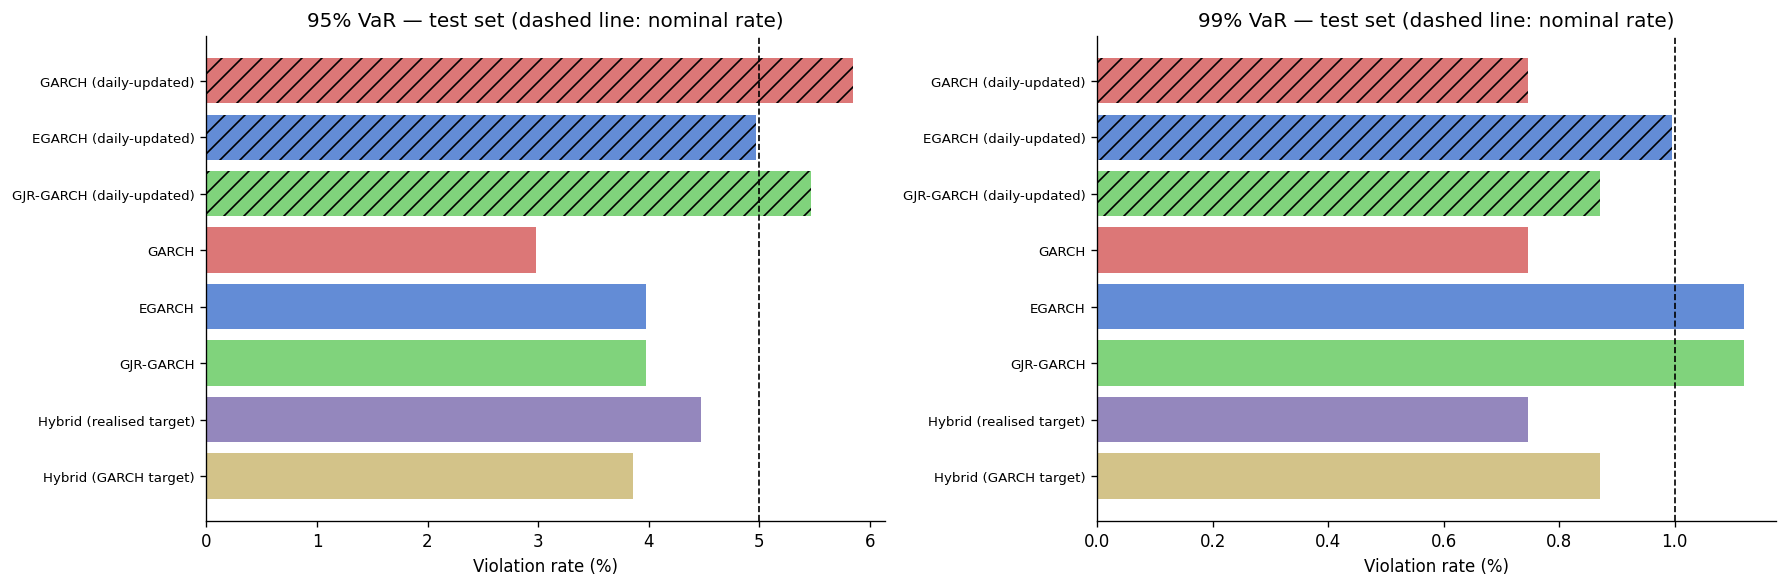

In [23]:
compare = pd.concat([backtest_tvt[backtest_tvt['Split'] == 'Test'], sensitivity[sensitivity['Split'] == 'Test']])
order   = [f'{n} (daily-updated)' for n in GARCH_NAMES] + MODEL_NAMES
palette = {**COLORS, **{f'{n} (daily-updated)': c for n, c in [(k, COLORS[k]) for k in GARCH_NAMES]}}

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=False)
for ax, cl in zip(axes, CONF_LEVELS):
    sub  = compare[compare['CL'] == cl].set_index('Model').loc[order]
    bars = ax.barh(range(len(order)), sub['Violation Rate (%)'], color=[palette[m] for m in order], alpha=0.85)
    for bar, m in zip(bars, order):
        if 'daily-updated' in m:
            bar.set_hatch('//')
    ax.axvline((1 - cl) * 100, color='black', ls='--', lw=1)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=8)
    ax.set_xlabel('Violation rate (%)')
    ax.set_title(f'{cl:.0%} VaR — test set (dashed line: nominal rate)')
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'tvt_daily_updated_garch.png', bbox_inches='tight')
plt.show()


## 8. Persistence and Export

Both networks are saved in the native Keras format under new names, together with the scaler used by the selected configuration. Neither is refitted on the test set.

In [24]:
model_a.save(MODELS_DIR / 'lstm_hybrid_tvt_model.keras')
model_b.save(MODELS_DIR / 'lstm_garch_supervised_tvt_model.keras')
joblib.dump(scaler_a, MODELS_DIR / 'lstm_tvt_feature_scaler.joblib')

oos = pd.DataFrame(index=dates_by_split['Test'])
oos['actual_next_ret']  = actual_all.reindex(oos.index)
oos['realised_vol_abs'] = realised_next.reindex(oos.index)
for name in MODEL_NAMES:
    oos[f'{name}_sigma'] = predicted_vol(name, 'Test')
    for cl in CONF_LEVELS:
        oos[f'{name}_var_{int(cl * 100)}'] = var_store[('Test', name, cl)]
oos.to_csv(RESULTS_DIR / 'tvt_oos_predictions.csv')

for path in sorted(list(MODELS_DIR.glob('*tvt*')) + list(RESULTS_DIR.glob('tvt_*')) + list(TABLES_DIR.glob('tvt_*'))):
    print(f"{path.parent.name}/{path.name:45s} {path.stat().st_size / 1024:8.1f} KB")


models/lstm_garch_supervised_tvt_model.keras             97.1 KB
models/lstm_hybrid_tvt_model.keras                       97.1 KB
models/lstm_tvt_feature_scaler.joblib                     0.7 KB
results/tvt_daily_updated_garch_backtest.csv               1.4 KB
results/tvt_model_performance_by_split.csv                 1.3 KB
results/tvt_oos_predictions.csv                          272.1 KB
results/tvt_var_backtest_summary.csv                       2.2 KB
tables/tvt_grid_search.csv                                0.3 KB
tables/tvt_split_summary.csv                              0.3 KB


## 9. Discussion

**The three-way split reproduces the existing Hybrid result.** With training, validation and test sets separated explicitly, the LSTM supervised against realised volatility gives a test RMSE of 0.0095 (0.0098 in the existing notebook), violation rates of 4.48% and 0.75% at 95% and 99% (5.35% and 0.75% before), and passes the Christoffersen test at both levels (p = 0.30 and 0.76). The result therefore does not depend on how the validation data were handled. Nor does it depend much on the architecture: the four configurations differ by less than 0.1 in validation MSE (4.61 to 4.70), and the choice between the two 32-unit networks is a tie (4.605 against 4.609), so the selection of a 10-day look-back is not informative.

**Every model generalises worse than it fits.** R² against the realised-volatility proxy is positive on the training set for all five models (0.15 to 0.22) and negative on the validation (−0.21 to −0.04) and test sets (−0.61 to −0.25). GARCH shows the same pattern as the LSTM, and test volatility (19.2% annualised) was lower than in the training window (23.4%). The drop is therefore a property of the target and of the change of regime, not of the machine learning layer. On RMSE the differences between models on the test set are small (0.0095 to 0.0099) except for GARCH (0.0108).

**Supervising against GARCH adds nothing on the VaR metrics.** The network trained to reproduce the GARCH ensemble matches it closely on the training set (R² = 0.97) but only partly on the validation (0.55) and test sets (0.63), where the GARCH target is a walk-forward forecast that behaves differently from the in-sample fit. On the test set it is nonetheless indistinguishable from the network trained on realised volatility in RMSE (0.0095 for both) and passes the independence test (p = 0.14 at 95%, 0.73 at 99%), although its directional accuracy is lower (44.5% against 54.2%). A network that has only ever been asked to imitate GARCH ends up with the same VaR properties as one trained against realised volatility, which suggests that the supervision target is not what produces them.

**The classical benchmark in the existing comparison is handicapped.** Section 7.5 gives each GARCH model the same quarterly parameter estimates but updates its variance with every new return. On the same test dates all three models then pass both the Kupiec and the Christoffersen tests at both levels (Kupiec p ≥ 0.28, Christoffersen p between 0.48 and 0.87 at 95% and between 0.69 and 0.76 at 99%); EGARCH has a violation rate of 4.98% at 95%. Their RMSE (0.0085 to 0.0090) is lower than that of the Hybrid models (0.0095), and EGARCH and GJR-GARCH have an R² close to zero (+0.015 and −0.007) against −0.25 for the Hybrid. The independence failures of the GARCH models in the existing notebook (p = 0.03 to 0.04 at 95%) are therefore largely a consequence of holding the forecast fixed for a quarter, and the comparison between the frozen GARCH forecasts and the LSTM, which sees every new return, mixes two effects. Against daily-updated GARCH models this test window gives no evidence that the LSTM layer improves the VaR.

**Limitations.** There is a single test window of 805 days and a single training seed for each network. The validation set covers the 2020–2022 stress period, in which the Hybrid (6.98%) and the daily-updated GARCH models (7.1–7.3%) all under-cover at the 95% level and the Christoffersen test does not separate any model, so model selection on it says little about calmer regimes. The LSTM inputs are built from in-sample filtered volatility during training but from frozen multi-step forecasts at test time; building the inputs from daily-updated GARCH output in both periods, so that training and test features are constructed identically, is the natural next experiment and is not done here.